In [223]:
import tensorflow as tf
print(tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print(gpus)
#tf.debugging.set_log_device_placement(True)
gpus = tf.config.list_logical_devices('GPU')
strategy = tf.distribute.MirroredStrategy(gpus)

2.10.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Executing op VarHandleOp in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op AssignVariableOp in device /job:localhost/replica:0/task:0/device:GPU:0
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0',)


In [224]:
import numpy as np 
import os
import skimage.io as io
import skimage.transform as trans
import numpy as np
from keras.models import *
from keras.layers import *
from keras.optimizers import *
from keras.callbacks import ModelCheckpoint
from keras import backend as keras
from tqdm import tqdm

In [225]:
def unet(input_size = (256,256,3)):
    import keras
    inputs = Input(input_size)
    s = tf.keras.layers.Lambda(lambda x: x / 255)(inputs)
    conv1 = Conv2D(64, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(s)
    conv1 = Conv2D(64, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv1)
    pool1 = MaxPooling2D(pool_size=(2, 2))(conv1)
    
    conv2 = Conv2D(128, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(pool1)
    conv2 = Conv2D(128, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv2)
    pool2 = MaxPooling2D(pool_size=(2, 2))(conv2)
    
    conv3 = Conv2D(256, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(pool2)
    conv3 = Conv2D(256, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv3)
    pool3 = MaxPooling2D(pool_size=(2, 2))(conv3)
    
    conv4 = Conv2D(512, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(pool3)
    conv4 = Conv2D(512, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv4)
    drop4 = Dropout(0.5)(conv4)
    pool4 = MaxPooling2D(pool_size=(2, 2))(drop4)

    conv5 = Conv2D(1024, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(pool4)
    conv5 = Conv2D(1024, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv5)
    drop5 = Dropout(0.5)(conv5)

    up6 = Conv2D(512, 2, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(UpSampling2D(size = (2,2))(drop5))
    merge6 = concatenate([drop4,up6], axis = 3)
    conv6 = Conv2D(512, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(merge6)
    conv6 = Conv2D(512, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv6)

    up7 = Conv2D(256, 2, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(UpSampling2D(size = (2,2))(conv6))
    merge7 = concatenate([conv3,up7], axis = 3)
    conv7 = Conv2D(256, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(merge7)
    conv7 = Conv2D(256, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv7)

    up8 = Conv2D(128, 2, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(UpSampling2D(size = (2,2))(conv7))
    merge8 = concatenate([conv2,up8], axis = 3)
    conv8 = Conv2D(128, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(merge8)
    conv8 = Conv2D(128, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv8)

    up9 = Conv2D(64, 2, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(UpSampling2D(size = (2,2))(conv8))
    merge9 = concatenate([conv1,up9], axis = 3)
    conv9 = Conv2D(64, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(merge9)
    conv9 = Conv2D(64, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv9)
    conv9 = Conv2D(2, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv9)
    conv10 = Conv2D(1, 1, activation = 'sigmoid')(conv9)

    model = Model(inputs = inputs, outputs = conv10)

    model.compile(optimizer=Adam(), loss="binary_crossentropy", metrics=["accuracy"])

    model.summary()

    return model

In [226]:
folder_path = os.path.join(os.getcwd(), "dataSet_train")
input_folder_path = os.path.join(folder_path, 'input')
output_folder_path = os.path.join(folder_path, 'output')
dataset_csv = os.path.join(folder_path, "data.csv")

In [227]:
import pandas as pd

df = pd.read_csv(dataset_csv)

print(df.sample()) 

                                                     X  \
821  E:\pers\mouhib\dataSet_train\input\TCGA_DU_640...   

                                                     Y  
821  E:\pers\mouhib\dataSet_train\output\TCGA_DU_64...  


In [228]:
X = df['X']
Y = df['Y']

In [229]:
import matplotlib.pyplot  as plt
import matplotlib.image as mpimg

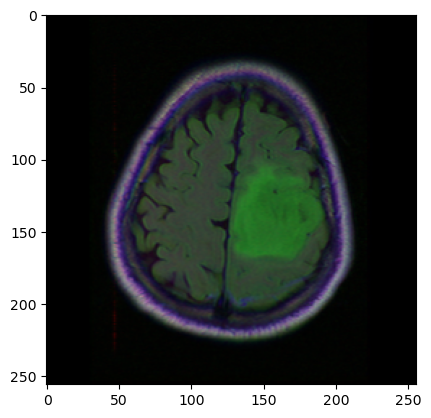

In [230]:
img=mpimg.imread(X[50])
plt.imshow(img, cmap="gray")

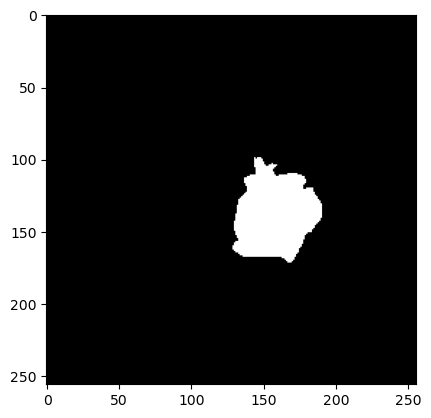

In [231]:
img=mpimg.imread(Y[50])
plt.imshow(img, cmap="gray")

In [232]:
X_train = np.zeros((len(X),128,128,3),dtype=np.uint8)
Y_train = np.zeros((len(Y),128,128,1),dtype=np.uint8)

In [233]:
from skimage.io import imread, imshow
from skimage.transform import resize
for n, image in tqdm(enumerate(X), total=len(X)):
    img = imread(image)[:,:,:3]  
    img = resize(img, (128, 128), mode='constant', preserve_range=True)
    X_train[n] = img

100%|█████████████████████████████████████████████████████████████████████████████████████████| 3929/3929 [00:38<00:00, 101.95it/s]


In [234]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
for n, image in tqdm(enumerate(Y), total=len(X)):
    mask = np.zeros((128, 128, 1), dtype=np.bool_)
    mask_ = mpimg.imread(image)
    mask_ = np.expand_dims(trans.resize(
        mask_, (128, 128), mode="constant", preserve_range=True), axis=-1)
    # X_train[n] = img
    mask = np.maximum(mask, mask_)
    mask = img_to_array(mask)/ 255.0
    mask = (mask > 0.5).astype(np.float32) 
    Y_train[n] = mask

100%|█████████████████████████████████████████████████████████████████████████████████████████| 3929/3929 [00:11<00:00, 339.09it/s]


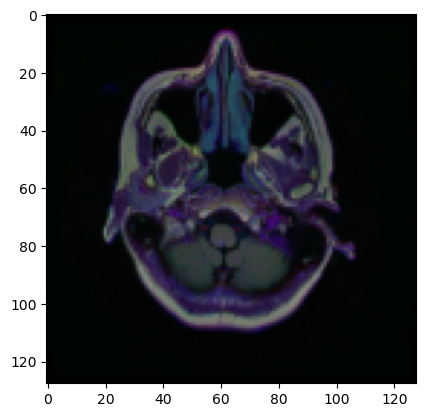

(128, 128, 1)
(128, 128, 3)


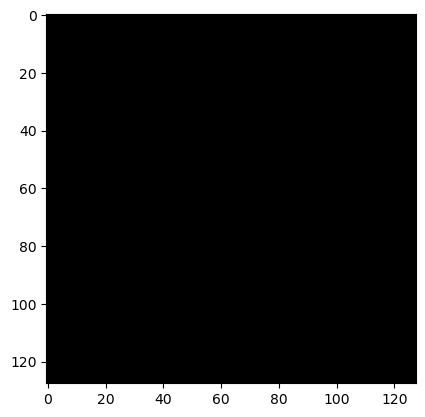

In [235]:
import random
n = random.randint(0,len(X))
plt.imshow(X_train[n])
plt.show()
plt.imshow(np.squeeze(Y_train[n]),cmap="gray")
print(Y_train[n].shape)
print(X_train[n].shape)
plt.show()

In [236]:
gpus = tf.config.list_physical_devices()
print(gpus)

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [237]:
checkpoint_path = './training/weight{epoch:04d}.h5'
checkpoint_dir = os.path.dirname(checkpoint_path)
callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                 save_weights_only=True,
                                                 mode='auto', save_freq='epoch',
                                                 monitor='val_loss',
                                                 save_best_only=False,
                                                 verbose=1)

In [238]:
os.environ["CUDA_VISIBLE_DEVICES"]="0"
try:
    gpu = tf.config.list_physical_devices('GPU')
    tf.config.experimental.set_memory_growth(gpu[0], True)
    
    tf.keras.backend.clear_session()
except Exception as e:
    print(e)

Physical devices cannot be modified after being initialized


In [239]:
tf.keras.backend.clear_session()
from tensorflow.keras import mixed_precision
policy = mixed_precision.Policy('mixed_float16')
mixed_precision.set_global_policy(policy)
config = tf.compat.v1.ConfigProto()
config.gpu_options.per_process_gpu_memory_fraction = 0.9
session = tf.compat.v1.Session(config=config)

In [240]:
physical_devices = tf.config.experimental.list_physical_devices('GPU')
for device in physical_devices:
    try:
        tf.config.experimental.set_memory_growth(device, True)
    except Exception as e:
        print(e)

Physical devices cannot be modified after being initialized


In [241]:
X_train = X_train / 255.0 
Y_train = Y_train / 255.0
print(X_train.shape)
print(Y_train.shape)

(3929, 128, 128, 3)
(3929, 128, 128, 1)


In [242]:
from sklearn.model_selection import train_test_split
print(X_train.shape)
print(Y_train.shape)

assert X_train.shape[0] == Y_train.shape[0], "Data has unequal sample sizes!"

x_train, x_test, y_train, y_test = train_test_split(
    X_train,Y_train, test_size=0.2, random_state=2024)

(3929, 128, 128, 3)
(3929, 128, 128, 1)


In [ ]:
with strategy.scope():
    model = unet(input_size = (128,128,3))
    res = model.fit(x_train,
                    y_train,
                    validation_split=0.1,
                    batch_size=64,epochs=50,
                    callbacks=[callback])

Executing op _EagerConst in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op _EagerConst in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op StatelessRandomGetKeyCounter in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op StatelessTruncatedNormalV2 in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op Mul in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op AddV2 in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op VarHandleOp in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op AssignVariableOp in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op NoOp in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op ReadVariableOp in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op Identity in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op ReadVariableOp in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op Identity

In [244]:
model.save("model.keras")

In [245]:
new_model = tf.keras.models.load_model('model.keras')

Executing op _EagerConst in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op _EagerConst in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op StatelessRandomGetKeyCounter in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op StatelessTruncatedNormalV2 in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op Mul in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op AddV2 in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op VarHandleOp in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op AssignVariableOp in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op _EagerConst in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op Fill in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op VarHandleOp in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op AssignVariableOp in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op _Eager

In [246]:
print("Evaluate on test data")
results = new_model.evaluate(x_test, y_test, batch_size=128)
print("*"*10)
print("test loss, test acc:", results)

predictions = new_model.predict(X_train[25:26])
print("predictions shape:", predictions.shape)

Evaluate on test data
Executing op _EagerConst in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op _EagerConst in device /job:localhost/replica:0/task:0/device:GPU:0
Executing op RangeDataset in device /job:localhost/replica:0/task:0/device:CPU:0
Executing op RepeatDataset in device /job:localhost/replica:0/task:0/device:CPU:0
Executing op MapDataset in device /job:localhost/replica:0/task:0/device:CPU:0
Executing op PrefetchDataset in device /job:localhost/replica:0/task:0/device:CPU:0
Executing op FlatMapDataset in device /job:localhost/replica:0/task:0/device:CPU:0
Executing op TensorDataset in device /job:localhost/replica:0/task:0/device:CPU:0
Executing op RepeatDataset in device /job:localhost/replica:0/task:0/device:CPU:0
Executing op ZipDataset in device /job:localhost/replica:0/task:0/device:CPU:0
Executing op ParallelMapDatasetV2 in device /job:localhost/replica:0/task:0/device:CPU:0
Executing op OptionsDataset in device /job:localhost/replica:0/task:0/device:

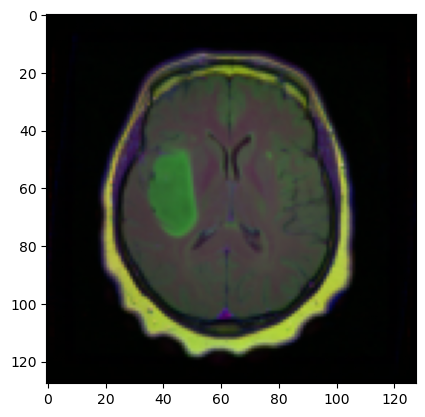

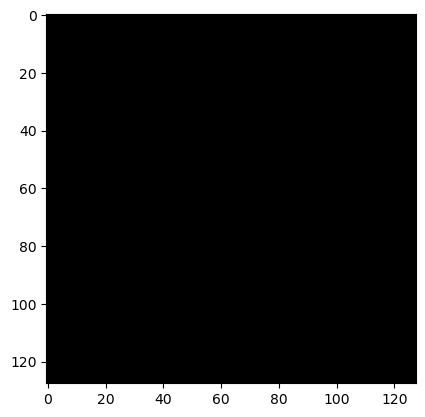

In [248]:
plt.imshow(X_train[25:26][0])
plt.show()
plt.imshow(predictions[0],cmap="gray")